# Machine Design Class 1
## Motor selection and key connections
**Team data:** 17 km/h, 500 mm sprocket pitch diameter, 4.4 kW.

Run the cells from top to bottom. This notebook only needs NumPy and Matplotlib. It uses direct equations and printed results, with the graphs displayed below their cells. There is no separate calculation file.

The shaft diameters, efficiencies, application factor and material strengths below are preliminary assumptions. They must be reviewed during the later belt, shaft and gear design.

In [37]:
import numpy as np
import matplotlib.pyplot as plt

## 1 Given values
Power is mechanical power in kW; shaft speeds are in rpm. The assignment specifies 1500 rpm and a target belt-to-gear ratio split of 3:5.

In [38]:
v = 17 / 3.6       # chain speed [m/s]
D_s = 500 / 1000   # sprocket pitch diameter [m]
P_load = 4.4       # useful chain power [kW]
n_motor = 1500     # motor speed [rpm]
life = 10 * 250 * 20
print(f"Required operating life = {life} h")

Required operating life = 50000 h


## 2 Speeds and transmission ratios
$$n_s=\frac{60v}{\pi D_s},\qquad i_{total}=\frac{n_{motor}}{n_s}$$
Since $i_b/i_g=3/5$ and $i_b i_g=i_{total}$, $i_b=\sqrt{0.6i_{total}}$.

In [39]:
n_target = 60 * v / (np.pi * D_s)
i_total_target = n_motor / n_target
i_b_target = np.sqrt(0.6 * i_total_target)
i_g_target = i_total_target / i_b_target
print(f"Required sprocket speed = {n_target:.3f} rpm")
print(f"Desired total ratio = {i_total_target:.5f}")
print(f"Desired belt ratio = {i_b_target:.5f}")
print(f"Desired gear ratio = {i_g_target:.5f}")

Required sprocket speed = 180.376 rpm
Desired total ratio = 8.31598
Desired belt ratio = 2.23374
Desired gear ratio = 3.72290


Use trial pulleys of 140 and 315 mm and gears with 21 and 79 teeth. The pinion has 19–24 teeth as required, and 21 and 79 have no common divisor. These are preliminary sizes, pending the later belt and gear checks.

In [40]:
d_pulley_motor = 140   # datum diameter [mm]
d_pulley_driven = 315  # datum diameter [mm]
z_pinion = 21
z_gear = 79

i_b = d_pulley_driven / d_pulley_motor
i_g = z_gear / z_pinion
n_input = n_motor / i_b
n_output = n_input / i_g
v_actual = np.pi * D_s * n_output / 60
speed_error = 100 * (v_actual / v - 1)
print(f"Belt ratio = {i_b:.5f}; gear ratio = {i_g:.5f}")
print(f"Ratio split = {i_b / i_g:.5f} (target 0.6)")
print(f"Input shaft = {n_input:.3f} rpm; output shaft = {n_output:.3f} rpm")
print(f"Cart speed = {v_actual * 3.6:.3f} km/h")
print(f"Speed error = {speed_error:.3f}% (allowed +/-5%)")

Belt ratio = 2.25000; gear ratio = 3.76190
Ratio split = 0.59810 (target 0.6)
Input shaft = 666.667 rpm; output shaft = 177.215 rpm
Cart speed = 16.702 km/h
Speed error = -1.752% (allowed +/-5%)


## 3 Application factor and efficiency
Table 3-5b in **5 - Tables belts.pdf, page 9** gives $K_A=1.6$ for its printed example: an electric motor, moderate starts, full load with medium shocks and 8 hours/day. Our duty is 20 hours/day. Reading toward the 24-hour line, we adopt **$K_A=1.8$ as a rounded preliminary estimate**. It is not a measured load factor.

We assume 95% belt efficiency, 98% gearbox efficiency including its bearings and seals, and 99% for the coupling and sprocket supports. The motor rating is mechanical output, so electrical motor efficiency is not included again.
$$P_{motor,design}=K_A\frac{P_{load}}{\eta_{total}}$$

In [41]:
K_A = 1.8
eta_belt = 0.95
eta_gearbox = 0.98
eta_downstream = 0.99
eta_total = eta_belt * eta_gearbox * eta_downstream
P_motor_nom = P_load / eta_total
P_motor_design = K_A * P_motor_nom

# Relevant neighbouring standard ratings from Table 16-21
motor_ratings = np.array([5.5, 7.5, 11, 15, 18.5, 22])
P_motor = motor_ratings[motor_ratings >= P_motor_design][0]
print(f"Total efficiency = {eta_total:.5f}")
print(f"Nominal motor power required = {P_motor_nom:.3f} kW")
print(f"Design motor power required = {P_motor_design:.3f} kW")
print(f"Selected standard motor = {P_motor:g} kW")

Total efficiency = 0.92169
Nominal motor power required = 4.774 kW
Design motor power required = 8.593 kW
Selected standard motor = 11 kW


At 1500 rpm, Table 16-21 (**belts PDF, page 8**) gives the 11 kW, frame 160M row with a 42 × 110 mm shaft end and 140 mm reference SPZ pulley. Its four grooves are reference table data; the belt capacity and number of belts still need to be calculated.

## 4 Influence of the application factor
**Question:** How does $K_A$ change the required motor power? Hold the chain power fixed and vary $K_A$ from 1.0 to 2.2. The shaded band shows assumed total efficiencies from 0.88 to 0.95.

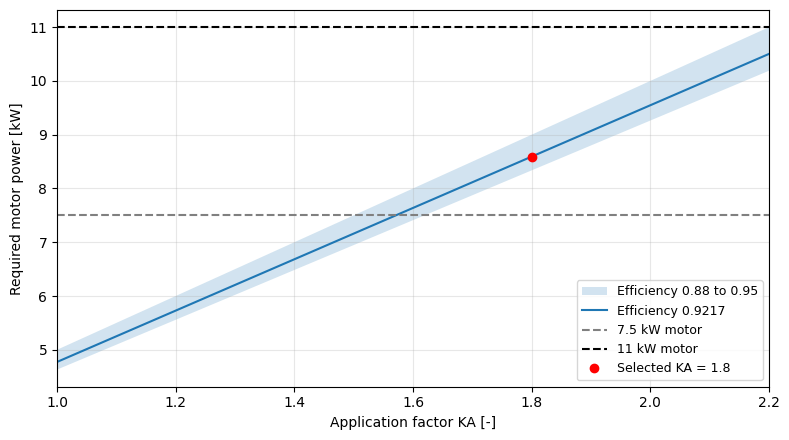

In [42]:
K_A_values = np.linspace(1.0, 2.2, 100)
P_values = K_A_values * P_load / eta_total

plt.figure(figsize=(8, 4.5))
plt.fill_between(K_A_values, K_A_values * P_load / 0.95,
                 K_A_values * P_load / 0.88, alpha=0.2,
                 label="Efficiency 0.88 to 0.95")
plt.plot(K_A_values, P_values, label=f"Efficiency {eta_total:.4f}")
plt.axhline(7.5, color="grey", linestyle="--", label="7.5 kW motor")
plt.axhline(11, color="black", linestyle="--", label="11 kW motor")
plt.plot(K_A, P_motor_design, "ro", label="Selected KA = 1.8")
plt.xlabel("Application factor KA [-]")
plt.ylabel("Required motor power [kW]")
plt.xlim(1.0, 2.2)
plt.grid(alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [43]:
K_A_limit_7_5 = 7.5 * eta_total / P_load
P_at_KA_1_25 = 1.25 * P_load / eta_total
print(f"Largest KA for a 7.5 kW motor = {K_A_limit_7_5:.3f}")
print(f"At KA = 1.25, required power = {P_at_KA_1_25:.3f} kW")
print(f"At KA = 1.8, efficiency range gives {K_A * P_load / 0.95:.2f}")
print(f"to {K_A * P_load / 0.88:.2f} kW")

Largest KA for a 7.5 kW motor = 1.571
At KA = 1.25, required power = 5.967 kW
At KA = 1.8, efficiency range gives 8.34
to 9.00 kW


**Result and trust:** The straight line follows from the power equation; at KA = 1.8 it reproduces 8.59 kW. Even the efficiency range gives more than 7.5 kW but less than 11 kW.

**Design impact:** We select 11 kW. A 7.5 kW motor would require KA no greater than about 1.57. The graph checks the effect of the assumed duty; it does not prove that KA = 1.8 describes the real machine.

## 5 Power and torque at each shaft
$$T=\frac{1000P}{2\pi n/60} \quad [\mathrm{Nm}]$$
There are two separate load cases: (1) $K_A$ times the nominal operating torque; (2) torque at the selected motor's full continuous rating. We do **not** apply $K_A$ again to the second case. Starting and stall torque are separate later checks.

In [44]:
P_input_nom = P_motor_nom * eta_belt
P_output_nom = P_input_nom * eta_gearbox
T_motor_nom = 1000 * P_motor_nom / (2 * np.pi * n_motor / 60)
T_input_nom = 1000 * P_input_nom / (2 * np.pi * n_input / 60)
T_output_nom = 1000 * P_output_nom / (2 * np.pi * n_output / 60)
T_sprocket_nom = 1000 * P_load / (2 * np.pi * n_output / 60)

T_input_design = K_A * T_input_nom
T_output_design = K_A * T_output_nom
T_motor_rated = 1000 * P_motor / (2 * np.pi * n_motor / 60)
T_input_rated = 1000 * P_motor * eta_belt / (2 * np.pi * n_input / 60)
T_output_rated = 1000 * P_motor * eta_belt * eta_gearbox / (2 * np.pi * n_output / 60)
T_sprocket_rated = T_output_rated * eta_downstream

print("Station       Nominal T    KA load T    Rated T [Nm]")
print(f"Motor         {T_motor_nom:9.2f}    {K_A*T_motor_nom:9.2f}    {T_motor_rated:9.2f}")
print(f"Gearbox input {T_input_nom:9.2f}    {T_input_design:9.2f}    {T_input_rated:9.2f}")
print(f"Gearbox output{T_output_nom:9.2f}    {T_output_design:9.2f}    {T_output_rated:9.2f}")
print(f"Sprocket      {T_sprocket_nom:9.2f}    {K_A*T_sprocket_nom:9.2f}    {T_sprocket_rated:9.2f}")

Station       Nominal T    KA load T    Rated T [Nm]
Motor             30.39        54.70        70.03
Gearbox input     64.96       116.93       149.69
Gearbox output   239.49       431.08       551.84
Sprocket         237.10       426.77       546.32


## 6 Materials and preliminary shaft seats
The effective steel yield strength is required to be at least 300 MPa for the 38Cr2 shaft, C45 key and 34CrMo4 hub. The assumed cast-iron bush must have effective tensile strength of at least 200 MPa. These are **minimum acceptance requirements, not certified grade properties**.

Following Table 12-1b (**connections PDF, page 4**) we use $p_{allow}=R_e/S$ for steel and $R_m/S$ for the brittle bush, with chosen $S=2$. The steel value is deliberately more conservative than the table's suggested flat-key factor range. For key shear, $\tau_{allow}=R_e/(\sqrt{3}S)$.

The shaft seats are preliminary choices. A pure-torsion screen at 60 MPa provides a starting point; it does not include bending, fatigue or keyway stress concentration.

In [45]:
R_e = 300     # minimum effective steel yield strength [MPa]
R_m_bush = 200 # minimum effective bush tensile strength [MPa]
S = 2
p_allow_input = min(R_e / S, R_m_bush / S)
p_allow_output = R_e / S
tau_allow = R_e / (np.sqrt(3) * S)
d_input_screen = (16 * T_input_rated * 1000 / (np.pi * 60))**(1/3)
d_output_screen = (16 * T_output_rated * 1000 / (np.pi * 60))**(1/3)
print(f"Allowable pressure: input {p_allow_input:.0f}; output {p_allow_output:.0f} MPa")
print(f"Allowable key shear = {tau_allow:.2f} MPa")
print(f"Pure torsion diameters = {d_input_screen:.2f} and {d_output_screen:.2f} mm")
print("Preliminary shaft seats: 35 mm and 50 mm")

Allowable pressure: input 100; output 150 MPa
Allowable key shear = 86.60 MPa
Pure torsion diameters = 23.33 and 36.05 mm
Preliminary shaft seats: 35 mm and 50 mm


## 7 Key calculation method
For one DIN 6885 Form A key, the supplied course notebooks use:
$$T_{eq}=K_A T_{nom},\quad l'=l-b,\quad h'=0.45h,\quad \bar p=\frac{2\cdot1000T_{eq}K_\lambda}{d h' l'}$$
Here torque is in Nm and dimensions are in mm, giving pressure in MPa. Method C uses $K_\lambda=1$. n and \phi are both 1.

The extra sensitivity check uses full motor rating, $K_\lambda=1.2$ and the smaller height $\min(0.45h,h-t_1)$. **1.2 is an assumed sensitivity value, not an interpolated Method B result.** No friction capacity of the taper-lock bush is credited.

Key sections and depths below are selected manually from Table 12-2a (**connections PDF, page 5**). If you change shaft diameter, reselect these values from that table.

### Driven pulley key
Choose a 35 mm shaft, a 10 × 8 mm key section and a 45 mm nominal length. A 50.8 mm long Fenner 3020-35 bush is a geometric candidate, subject to final pulley compatibility and contact geometry.

In [46]:
d_1 = 35     # shaft diameter [mm]
b_1 = 10     # key width [mm]
h_1 = 8      # key height [mm]
l_1 = 45     # nominal key length [mm]
t_1 = 5      # shaft keyway depth [mm]
t_2 = 3.3    # hub keyway depth [mm]
L_hub_1 = 50.8
l_eff_1 = l_1 - b_1
h_eff_1 = 0.45 * h_1
h_check_1 = h_eff_1
K_lambda = 1.2

p_1_design = 2 * T_input_design * 1000 / (d_1 * h_eff_1 * l_eff_1)
p_1_rated = 2 * T_input_rated * 1000 / (d_1 * h_eff_1 * l_eff_1)
p_1_check = 2 * T_input_rated * 1000 * K_lambda / (d_1 * h_check_1 * l_eff_1)
tau_1 = 2 * T_input_rated * 1000 / (d_1 * b_1 * l_eff_1)
l_1_min = b_1 + 2 * T_input_rated * 1000 * K_lambda / (d_1 * h_check_1 * p_allow_input)
h_1_min = 2 * T_input_rated * 1000 * K_lambda / (d_1 * l_eff_1 * p_allow_input)

print(f"Effective length = {l_eff_1:.0f} mm; Method C height = {h_eff_1:.2f} mm")
print(f"KA load pressure = {p_1_design:.2f} MPa")
print(f"Rated load pressure = {p_1_rated:.2f} MPa")
print(f"Sensitivity pressure = {p_1_check:.2f} MPa (limit {p_allow_input:.0f})")
print(f"Shear = {tau_1:.2f} MPa (limit {tau_allow:.2f})")
print(f"Minimum nominal length = {l_1_min:.2f} mm -> choose 45 mm")
print(f"Minimum contact height = {h_1_min:.4f} mm")
print("Pressure passes:", p_1_check <= p_allow_input)
print("Length fits:", l_1 < L_hub_1 and l_eff_1 <= 1.3 * d_1)

Effective length = 35 mm; Method C height = 3.60 mm
KA load pressure = 53.03 MPa
Rated load pressure = 67.88 MPa
Sensitivity pressure = 81.46 MPa (limit 100)
Shear = 24.44 MPa (limit 86.60)
Minimum nominal length = 38.51 mm -> choose 45 mm
Minimum contact height = 2.9326 mm
Pressure passes: True
Length fits: True


### Output gear key
At exactly 50 mm, use the “over 44 up to 50 mm” row: 14 × 9 mm. Choose a 70 mm key and a preliminary 75 mm hub. The slightly longer-than-usual steel hub is needed for the selected key engagement.

In [47]:
d_2 = 50
b_2 = 14
h_2 = 9
l_2 = 70
t_1_output = 5.5
t_2_output = 3.8
L_hub_2 = 75
l_eff_2 = l_2 - b_2
h_eff_2 = 0.45 * h_2
h_check_2 = h_eff_2

p_2_design = 2 * T_output_design * 1000 / (d_2 * h_eff_2 * l_eff_2)
p_2_rated = 2 * T_output_rated * 1000 / (d_2 * h_eff_2 * l_eff_2)
p_2_check = 2 * T_output_rated * 1000 * K_lambda / (d_2 * h_check_2 * l_eff_2)
tau_2 = 2 * T_output_rated * 1000 / (d_2 * b_2 * l_eff_2)
l_2_min = b_2 + 2 * T_output_rated * 1000 * K_lambda / (d_2 * h_check_2 * p_allow_output)
h_2_min = 2 * T_output_rated * 1000 * K_lambda / (d_2 * l_eff_2 * p_allow_output)

print(f"Effective length = {l_eff_2:.0f} mm; Method C height = {h_eff_2:.2f} mm")
print(f"KA load pressure = {p_2_design:.2f} MPa")
print(f"Rated load pressure = {p_2_rated:.2f} MPa")
print(f"Sensitivity pressure = {p_2_check:.2f} MPa (limit {p_allow_output:.0f})")
print(f"Shear = {tau_2:.2f} MPa (limit {tau_allow:.2f})")
print(f"Minimum nominal length = {l_2_min:.2f} mm -> choose 70 mm")
print(f"Minimum contact height = {h_2_min:.4f} mm")
print("Pressure passes:", p_2_check <= p_allow_output)
print("Length fits:", l_2 < L_hub_2 and l_eff_2 <= 1.3 * d_2)

Effective length = 56 mm; Method C height = 4.05 mm
KA load pressure = 76.03 MPa
Rated load pressure = 97.33 MPa
Sensitivity pressure = 116.79 MPa (limit 150)
Shear = 28.16 MPa (limit 86.60)
Minimum nominal length = 57.60 mm -> choose 70 mm
Minimum contact height = 3.1534 mm
Pressure passes: True
Length fits: True


## 8 Influence of output key length
**Question:** How much nominal length is needed for a 14 × 9 mm Form A key on the 50 mm output shaft? Keep torque and material limits fixed and vary $l$. The plot is average contact pressure versus the chosen length; it is not the pressure distribution along an installed key.

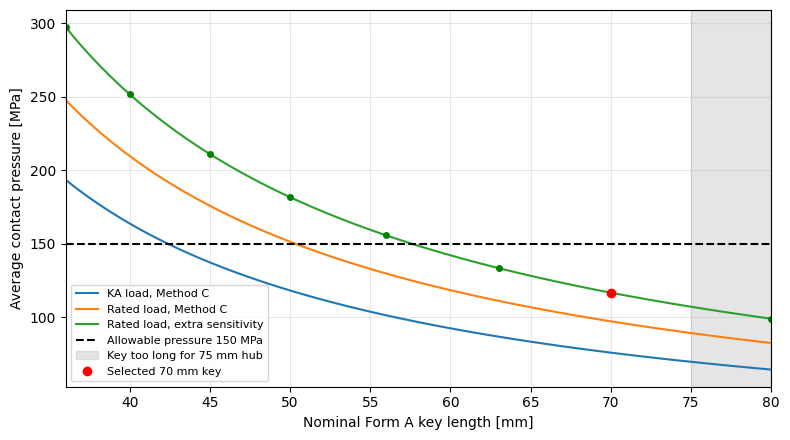

In [48]:
l_values = np.linspace(36, 80, 200)
p_design_values = 2 * T_output_design * 1000 / (d_2 * h_eff_2 * (l_values - b_2))
p_rated_values = 2 * T_output_rated * 1000 / (d_2 * h_eff_2 * (l_values - b_2))
p_check_values = 2 * T_output_rated * 1000 * K_lambda / (d_2 * h_check_2 * (l_values - b_2))
standard_lengths = np.array([36, 40, 45, 50, 56, 63, 70, 80])
p_standard = 2 * T_output_rated * 1000 * K_lambda / (d_2 * h_check_2 * (standard_lengths - b_2))

plt.figure(figsize=(8, 4.5))
plt.plot(l_values, p_design_values, label="KA load, Method C")
plt.plot(l_values, p_rated_values, label="Rated load, Method C")
plt.plot(l_values, p_check_values, label="Rated load, extra sensitivity")
plt.plot(standard_lengths, p_standard, "o", color="green", markersize=4)
plt.axhline(p_allow_output, color="black", linestyle="--", label="Allowable pressure 150 MPa")
plt.axvspan(L_hub_2, 80, color="grey", alpha=0.2, label="Key too long for 75 mm hub")
plt.plot(l_2, p_2_check, "ro", label="Selected 70 mm key")
plt.xlabel("Nominal Form A key length [mm]")
plt.ylabel("Average contact pressure [MPa]")
plt.xlim(36, 80)
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [49]:
p_at_63 = 2 * T_output_rated * 1000 * K_lambda / (d_2 * h_check_2 * (63 - b_2))
print(f"63 mm key: {p_at_63:.2f} MPa -> below 150 MPa")
print(f"70 mm key: {p_2_check:.2f} MPa -> below 150 MPa")

63 mm key: 133.48 MPa -> below 150 MPa
70 mm key: 116.79 MPa -> below 150 MPa


**Result and trust:** Pressure decreases as 1/(l − b), as expected from the contact-area equation. The extra check needs a nominal length of 64.45 mm; 63 mm fails but the next standard length, 70 mm, passes.

**Design impact:** Retain the 70 mm key in the 75 mm hub. Its effective length is 56 mm, below 1.3d = 65 mm. Longer keys cannot be used without checking the available hub length.

## 9 Independent checks
Reproduce the supplied course example and independently calculate sprocket torque from chain pull multiplied by pitch radius.

In [50]:
p_example = 2 * (450 * 1.5) * 1000 / (60 * (0.45 * 11) * (80 - 18))
F_chain = P_load * 1000 / v_actual
T_from_force = F_chain * D_s / 2
print(f"Course example = {p_example:.5f} MPa (reference 73.31 MPa)")
print(f"Force-radius torque = {T_from_force:.5f} Nm")
print(f"Power-speed torque = {T_sprocket_nom:.5f} Nm")
print("Speed tolerance passes:", abs(speed_error) <= 5)
print("Both key shear checks pass:", tau_1 <= tau_allow and tau_2 <= tau_allow)

Course example = 73.31378 MPa (reference 73.31 MPa)
Force-radius torque = 237.09539 Nm
Power-speed torque = 237.09539 Nm
Speed tolerance passes: True
Both key shear checks pass: True


## 10 Fits and conclusion
For the output gear, the preliminary fit is H7/j6: a 50.000–50.025 mm bore and a 49.995–50.011 mm shaft. Maximum clearance is 0.030 mm; maximum interference is 0.011 mm. The easily mounted, non-reversing keyway fits are N9 in the shaft and JS9 in the hub, with h9 key width (Tables 2-1, 2-2 and 12-2b). The taper-lock assembly must follow its manufacturer’s fits.

The preliminary selections are **11 kW**, **10 × 8 × 45 mm pulley key**, and **14 × 9 × 63 mm output gear key**. The pulley key is close to its pressure limit in the additional sensitivity case: at least 2.933 mm effective contact height is needed, so chamfers and actual engagement matter. The output key requires at least 3.154 mm. Table 16-21 lists a breakdown/rated torque ratio of 3.6; continuous rated torque does not bound starting or stall torque.

Later work must check belt capacity, manufacturer compatibility, motor starting, shaft bending/fatigue and bearings. The 50 000 h life is a requirement, not a verified result.
